### [GALT] Vežba 2: Sintetička populacija zvezda

### <font color='yellow'>Ideja vežbe: Generisanje sintetičke populacije zvezda koristeći inicijalnu funkciju mass (initial mass function) i analiziranje Malmkvistove neobjektivnosti.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod


Statističko opisivanje zvezdanih populacija u astrofizici temelji se na dva ključna teorijska koncepta: raspodeli masa pri rođenju i rezultujućoj raspodeli luminoznosti.
1. Inicialna funkcija mase (_initial mass function_) definiše relativnu zastupljenost zvezda po jediničnom intervalu mase u trenutku njihovog formiranja. Prema empirijskom Salpeterovom zakonu (1955), ova raspodela prati funkciju stepenog zakona:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
Ovaj odnos ukazuje na izrazitu dominaciju zvezda malih masa u poređenju sa masivnim objektima.
Naravno, postoji mnogo modernijih IMF, npr. Miller-Scalo IMF, Chabrier IMF, ali u ovoj vežbi, jednostavnosti radi, koristićemo prvu predloženu. (https://articles.adsabs.harvard.edu/pdf/1955ApJ...121..161S)

2. Dok IMF opisuje maseni spektar, funkcija luminoznosti (LF) kvantifikuje gustinu broja zvezda po jedinici zapremine u opsegu određenog sjaja ili magnitude. Prelaz sa mase na luminoznost ostvaruje se putem relacije masa-luminoznost ($L \propto M^{3.5}$ za zvezde glavnog niza), čime se teorijske mase prevode u posmatračke veličine — apsolutne magnitude. U posmatračkoj astrofizici, poznavanje funkcije luminoznosti je neophodno za modelovanje efekata selekcije i ispravnu rekonstrukciju prostorne distribucije zvezdanih sistema.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

##### <font color="green">1. Semplovati 10000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Hint: Učili ste na astrostatistici kako se to radi, inverse transform sampling.)</font>

In [5]:
# Инверзно узорковање маса звијезда према Салпетеровој функцији
Ммин = 0.08
Ммакс = 200.0
α = 2.35
rng = np.random.default_rng(42)
# Салпетерова функција масе звијезда
def салпетер(м):
    return м**(-α)
# Узорковање маса звијезда по Салпетеровој функцији
def узорковање_звјезданих_маса(n_узорака):
    # Прављење узорака из равномјерне расподјеле
    u = rng.random(n_узорака)
    # Инверзна кумулативна функција за Салпетерову расподјелу
    m_узорака = (Ммин**(1-α) + u*(Ммакс**(1-α)-Ммин**(1-α)))**(1/(1-α))
    return m_узорака
# Генерисање 10000 звијезда и приказивање статистике
масе = узорковање_звјезданих_маса(10000)
print(f"Број звијезда: {len(масе)}")
print(f"Минимална узоркована маса: {масе.min():.4f} Маса Сунца")
print(f"Максимална узоркована маса: {масе.max():.4f} Маса Сунца")
print(f"Средња узоркована маса: {масе.mean():.4f} Маса Сунца")


Број звијезда: 10000
Минимална узоркована маса: 0.0800 Маса Сунца
Максимална узоркована маса: 124.8925 Маса Сунца
Средња узоркована маса: 0.2983 Маса Сунца


##### <font color="green">2. Odrediti luminoznost i apsolutnu magnitudu svih zvezda.</font>

In [7]:
# Одређивање луминозности и апсолутне магнитуде звијезда
L = масе**3.5
М_апсолутно = 4.83 - 2.5 * np.log10(L)
print(f"Средња луминозност: {L.mean():.4f} L☉")
print(f"Опсег апсолутних магнитуда: {М_апсолутно.min():.2f} до {М_апсолутно.max():.2f}")

Средња луминозност: 2345.7278 L☉
Опсег апсолутних магнитуда: -13.51 до 14.43


##### <font color="green">3. Pretpostavljajući da je maksimalna udaljenost zvezda 10kpc, i da su uniformno raspoređene u sferi, semplovati njihove udaljenosti i odrediti prividne magnitude i prikazati histogram (m).</font>

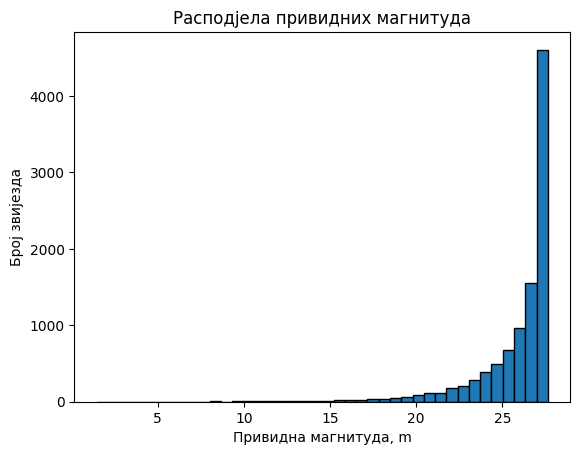

In [11]:
# Узорак удаљености звијезда у сфери полупречника 10 kpc
rng = np.random.default_rng(42)
удаљености = 10 * rng.random(len(масе))**(1/3)
# Привидне магнитуде (удаљеност је изражена у kpc)
м = М_апсолутно + 10 + 5 * np.log10(удаљености)
# Хистограм привидних магнитуда
plt.hist(м, bins=40, edgecolor="black")
plt.xlabel("Привидна магнитуда, m")
plt.ylabel("Број звијезда")
plt.title("Расподјела привидних магнитуда")
plt.show()

##### <font color="green">4. Analizirati kako se menja broj detektovanih zvezda u zavisnosti od udaljenosti za maksimalnu prividnu magnitudu koja može biti detektovana od 15, 18 i 22.</font>

In [14]:
# Број детектованих звијезда за различите граничне магнитуде
for м_граница in [15, 18, 22]:
    детектоване =  м <= м_граница
    print(f"М максимално = {м_граница}: {детектоване.sum()} од {len(м)} звијезда")

М максимално = 15: 68 од 10000 звијезда
М максимално = 18: 180 од 10000 звијезда
М максимално = 22: 721 од 10000 звијезда


##### <font color="green">5. Prikazati grafike zavisnosti apsolutne magnitude od udaljenosti i označiti različitim simbolima detektovane i nedektovane zvezde, za sve tri granične magnitude. (Malmkvistova neobjektivnost)</font>

In [ ]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
# Приказ Малмквистовог ефекта за изабрану граничну магнитуду
def прикази_Малмквист(м_граница):
    det = м <= м_граница
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(удаљености[det], М_апсолутно[det], s=18, color="tab:blue", marker="o", alpha=0.65, label=f"Детектоване ({det.sum()})")
    ax.scatter(удаљености[~det], М_апсолутно[~det], s=24, color="tab:orange", marker="x", alpha=0.75, label=f"Недетектоване ({(~det).sum()})")
    ax.set_xlabel("Удаљеност (kpc)", fontsize=16)
    ax.set_ylabel("Апсолутна магнитуда", fontsize=16)
    ax.set_title(f"Малмквистово дејство за граничну магнитуду m = {м_граница}", fontsize=18)
    ax.invert_yaxis()
    ax.grid(alpha=0.25)
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()
# Избор граничне магнитуде
маг_виџет = widgets.interactive(прикази_Малмквист,
    м_граница=widgets.Dropdown(options=[15, 18, 22],
        value=18, description="Гранична магнитуда:"))
display(маг_виџет)

interactive(children=(Dropdown(description='Гранична магнитуда:', index=1, options=(15, 18, 22), value=18), Ou…

Након разматрања резултата, примјећује се да постоји распон удаљености до које се за одређену магнитуду може детектовати звијезда. Међутим, како је привидна магнитуда у зависности и од растојања и од апсолутне магнитуде, тиме се лако могу одсјећи мање луминозне звијезде које су на већим удаљеностима, а због сличне апсолутне магнитуде су видљиве на мањим растојањима. Ово је познато као Малмквистова необјективност која се донекле може ублажити бољим детекторима који могу посматрати све удаљеније и удаљеније мање луминозне звијезде како би подаци што боље одговарали изворној, почетној популацији.